# Apple weight prediction
Predict an apple's weight (g) from its height, maximum diameter, perpendicular diameter and perimeter.

**Linear regression is the baseline.** Ridge, Lasso, Elastic Net and Kernel Ridge Regression (KRR) are compared against it.

### What we measure
Four measurements per apple, plus its weight (the target).

![Side view of an apple](image3.png)![Top view of an apple](image4.png)

## 1. Imports and chart settings

In [101]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_absolute_error

pio.templates.default = "plotly_white"

def show(fig, height=800):
    """Show a Plotly figure large, with readable fonts."""
    fig.update_layout(height=height, font=dict(size=16), title_font_size=24,
                      margin=dict(l=70, r=40, t=100, b=70))
    fig.show()

## 2. Load data
The `General` sheet already combines the apples measured by each person (the `source` column).

Four people measured the apples. Each dot below is one apple, colored by who measured it.

![Apples by person](image1.png)

In [104]:
df = pd.read_excel("manzanas.xlsx", sheet_name="General")


df.columns = ["height", "diam_max", "diam_perp", "perimeter", "weight", "source"]

FEATURES = ["height", "diam_max", "diam_perp", "perimeter"]
TARGET = "weight"

print("Rows:", len(df))
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
df.head()

Rows: 98
Missing values: 0
Duplicated rows: 0


,height,diam_max,diam_perp,perimeter,weight,source
0,6.5,7.4,7.2,23.2,156,Gael
1,6.2,7.2,7.0,22.5,143,Gael
2,6.7,7.6,7.4,23.9,172,Gael
3,5.9,6.8,6.7,21.5,126,Gael
4,6.2,7.1,7.0,22.3,143,Gael


In [105]:

df.describe().round(2)

,height,diam_max,diam_perp,perimeter,weight
count,98.00,98.00,98.00,98.00,98.00
mean,6.49,7.24,7.03,22.29,147.05
std,0.41,0.33,0.33,1.15,22.92
min,5.50,6.20,6.00,19.10,90.00
25%,6.20,7.00,6.80,21.52,133.25
50%,6.50,7.20,7.00,22.20,143.00
75%,6.80,7.40,7.20,23.00,165.00
max,7.30,8.10,7.90,25.60,196.00


## 3. Exploratory data analysis



### 3.1 Distributions

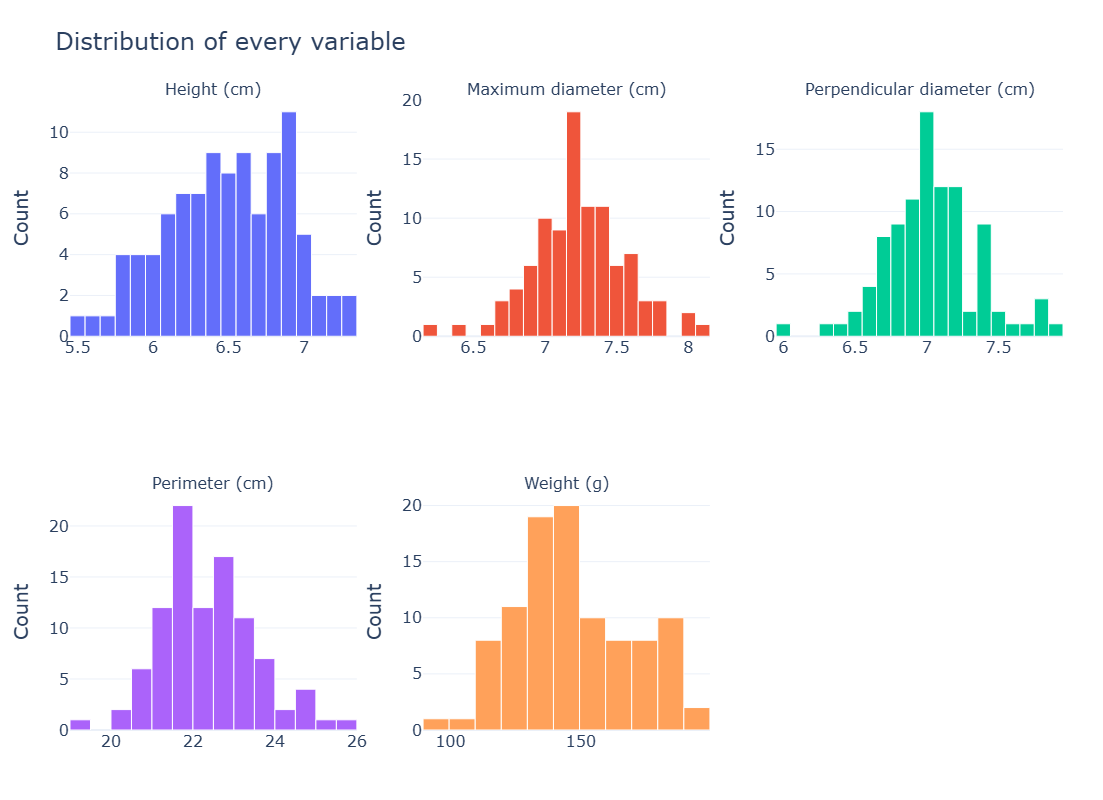

In [108]:
cols = FEATURES + [TARGET]
titles = ["Height (cm)", "Maximum diameter (cm)", "Perpendicular diameter (cm)", "Perimeter (cm)", "Weight (g)"]

fig = make_subplots(rows=2, cols=3, subplot_titles=titles)
for i, col in enumerate(cols):
    fig.add_trace(go.Histogram(x=df[col], nbinsx=20, name=col, showlegend=False,
                               marker_line=dict(width=1, color="white")),
                  row=i // 3 + 1, col=i % 3 + 1)
fig.update_layout(title="Distribution of every variable")
fig.update_yaxes(title_text="Count")
show(fig, height=800)

### 3.2 Every predictor against the weight
Each panel also shows the straight-line fit and the correlation `r`. Colors mark who measured the apple.

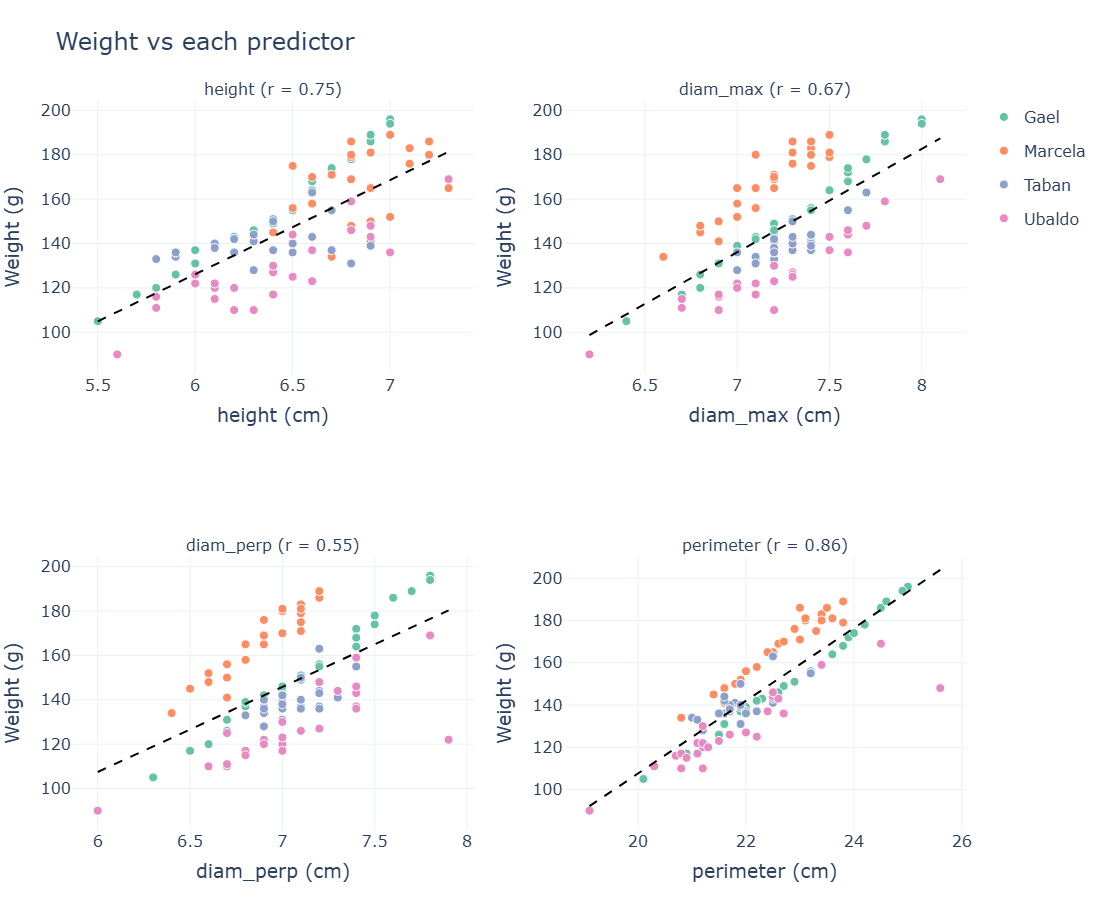

In [110]:
colors = dict(zip(sorted(df["source"].unique()), px.colors.qualitative.Set2))

fig = make_subplots(rows=2, cols=2, subplot_titles=[
    f"{f} (r = {df[f].corr(df[TARGET]):.2f})" for f in FEATURES])
for i, f in enumerate(FEATURES):
    r, c = i // 2 + 1, i % 2 + 1
    for src, g in df.groupby("source"):
        fig.add_trace(go.Scatter(x=g[f], y=g[TARGET], mode="markers", name=src,
                                 legendgroup=src, showlegend=(i == 0),
                                 marker=dict(size=9, color=colors[src], line=dict(width=1, color="white"))),
                      row=r, col=c)
    slope, intercept = np.polyfit(df[f], df[TARGET], 1)
    xs = np.array([df[f].min(), df[f].max()])
    fig.add_trace(go.Scatter(x=xs, y=slope * xs + intercept, mode="lines",
                             line=dict(color="black", dash="dash"), showlegend=False),
                  row=r, col=c)
    fig.update_xaxes(title_text=f"{f} (cm)", row=r, col=c)
    fig.update_yaxes(title_text="Weight (g)", row=r, col=c)
fig.update_layout(title="Weight vs each predictor")
show(fig, height=900)

### 3.3 Correlation between variables
The two diameters are strongly correlated with each other, and the perimeter is correlated with all the sizes.

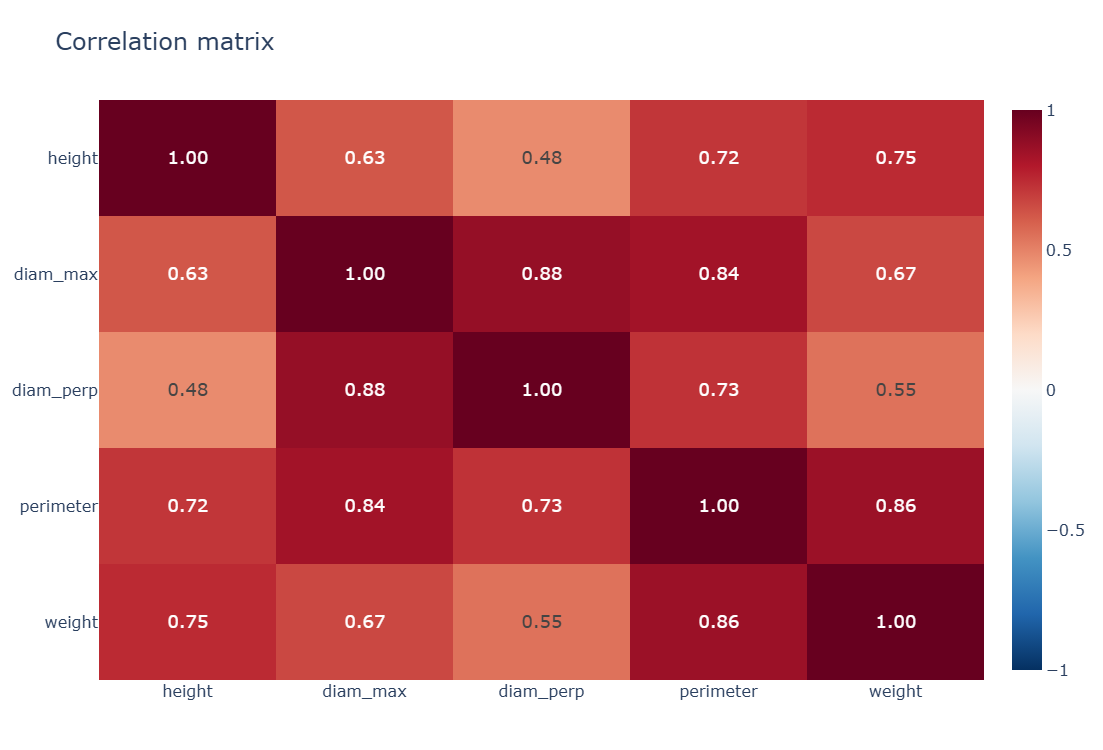

In [112]:
corr = df[FEATURES + [TARGET]].corr()
fig = px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                aspect="auto", title="Correlation matrix")
fig.update_traces(textfont_size=18)
show(fig, height=750)

### 3.4 Scatter matrix

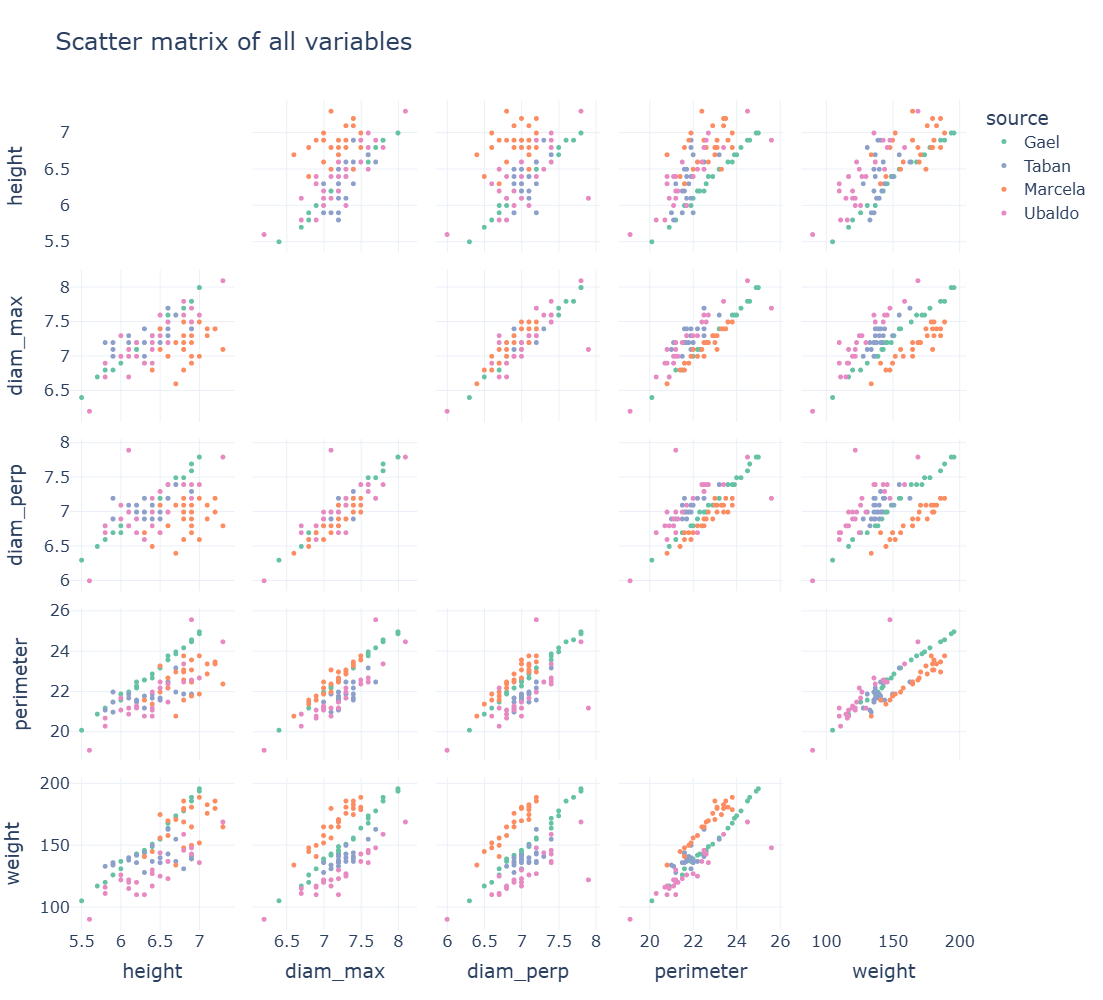

In [114]:
fig = px.scatter_matrix(df, dimensions=FEATURES + [TARGET], color="source",
                        color_discrete_map=colors, title="Scatter matrix of all variables")
fig.update_traces(diagonal_visible=False, marker=dict(size=5))
show(fig, height=1000)

### 3.5 Weight by Person (Gael , Taban , Marcelo and Ubaldo)


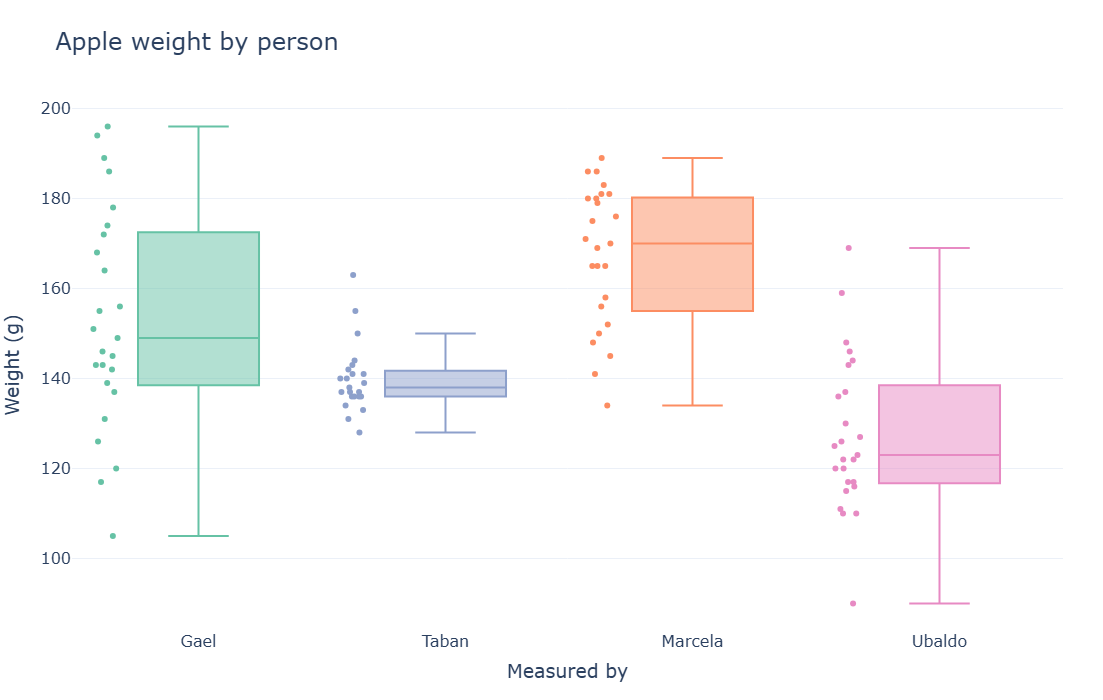

In [116]:
fig = px.box(df, x="source", y=TARGET, color="source", points="all",
             color_discrete_map=colors,
             labels={"source": "Measured by", "weight": "Weight (g)"},
             title="Apple weight by person")
fig.update_layout(showlegend=False)
show(fig, height=700)

## 4. Train / test split (80 / 20)

In [118]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Train:", len(X_train), "| Test:", len(X_test))

Train: 78 | Test: 20


## 5. Models
Every model starts with a `StandardScaler` (regularization needs the variables on the same scale).
Hyperparameters are chosen with 5-fold cross-validation on the **train** set only.

- **Linear (baseline)**: ordinary least squares. Minimizes the sum of squared errors, no regularization.
- **Ridge**: least squares + `alpha` * sum of squared coefficients (L2). Shrinks coefficients but never makes them exactly zero. Helps when predictors are correlated.
- **Lasso**: least squares + `alpha` * sum of absolute coefficients (L1). Can set coefficients exactly to zero, so it selects variables.
- **Elastic Net**: mix of L1 and L2 (`l1_ratio` controls the mix).
- **KRR (RBF)**: Ridge regression in a kernel space. With the RBF kernel the model is non-linear in the original variables. Weight grows roughly with volume (size cubed), so a mild curve is plausible. The cross-validation decides if it is needed.

In [120]:
linear = make_pipeline(StandardScaler(), LinearRegression())

ridge = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": np.logspace(-3, 3, 30)},
    cv=5, scoring="neg_mean_absolute_error")

lasso = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=100000)),
    {"lasso__alpha": np.logspace(-3, 1, 30)},
    cv=5, scoring="neg_mean_absolute_error")

enet = GridSearchCV(
    make_pipeline(StandardScaler(), ElasticNet(max_iter=100000)),
    {"elasticnet__alpha": np.logspace(-3, 1, 20),
     "elasticnet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    cv=5, scoring="neg_mean_absolute_error")

krr = GridSearchCV(
    make_pipeline(StandardScaler(), KernelRidge(kernel="rbf")),
    {"kernelridge__alpha": np.logspace(-3, 1, 10),
     "kernelridge__gamma": np.logspace(-3, 0, 10)},
    cv=5, scoring="neg_mean_absolute_error")

BASELINE = "Linear (baseline)"
models = {BASELINE: linear, "Ridge": ridge, "Lasso": lasso,
          "Elastic Net": enet, "KRR (RBF)": krr}

# KRR has no intercept, so we subtract the training mean before fitting
# and add it back after predicting.
y_mean = y_train.mean()

def fit_model(name, model):
    """Fit one model on the training set."""
    target = y_train - y_mean if name == "KRR (RBF)" else y_train
    model.fit(X_train, target)

def predict_weight(name, X_new):
    """Predict the weight in grams with the model called `name`."""
    pred = models[name].predict(X_new)
    return pred + y_mean if name == "KRR (RBF)" else pred

## 6. Fit and evaluate on the test set

In [122]:
results, predictions = {}, {}
for name, model in models.items():
    fit_model(name, model)
    predictions[name] = predict_weight(name, X_test)
    results[name] = mean_absolute_error(y_test, predictions[name])
    if hasattr(model, "best_params_"):
        print(f"{name} best params: {model.best_params_}")

Ridge best params: {'ridge__alpha': 0.001}
Lasso best params: {'lasso__alpha': 0.03290344562312668}
Elastic Net best params: {'elasticnet__alpha': 0.018329807108324356, 'elasticnet__l1_ratio': 0.9}
KRR (RBF) best params: {'kernelridge__alpha': 0.021544346900318832, 'kernelridge__gamma': 0.21544346900318823}


## 7. Compare against the linear baseline

In [124]:
comparison = pd.DataFrame({"Test MAE (g)": results})
comparison["Change vs baseline (%)"] = (comparison["Test MAE (g)"] / results[BASELINE] - 1) * 100
comparison = comparison.sort_values("Test MAE (g)")
comparison.round(2)

,Test MAE (g),Change vs baseline (%)
KRR (RBF),6.61,-25.63
Linear (baseline),8.88,0.00
Ridge,8.88,0.00
Lasso,8.89,0.05
Elastic Net,8.90,0.16


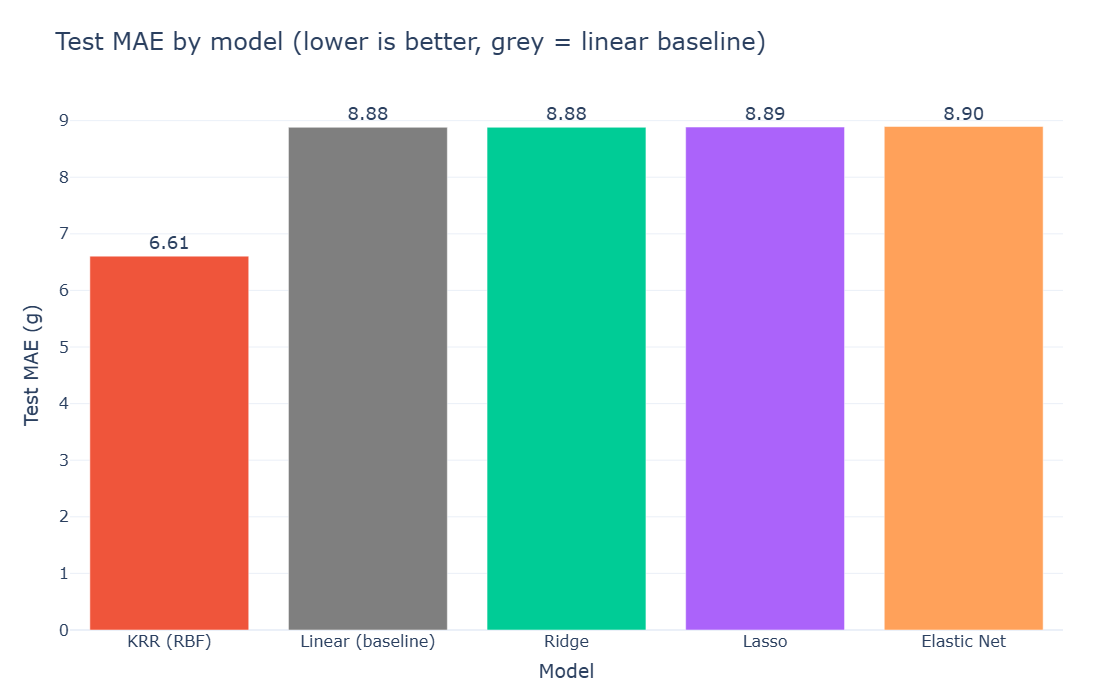

In [125]:
fig = px.bar(comparison.reset_index(names="Model"), x="Model", y="Test MAE (g)",
             color="Model", text_auto=".2f",
             color_discrete_map={BASELINE: "#7F7F7F"},
             title="Test MAE by model (lower is better, grey = linear baseline)")
fig.update_traces(textfont_size=18, textposition="outside")
fig.update_layout(showlegend=False)
show(fig, height=700)

### What the regularization did
Standardized coefficients of each linear model. Ridge shrinks them, Lasso can send some to exactly zero.

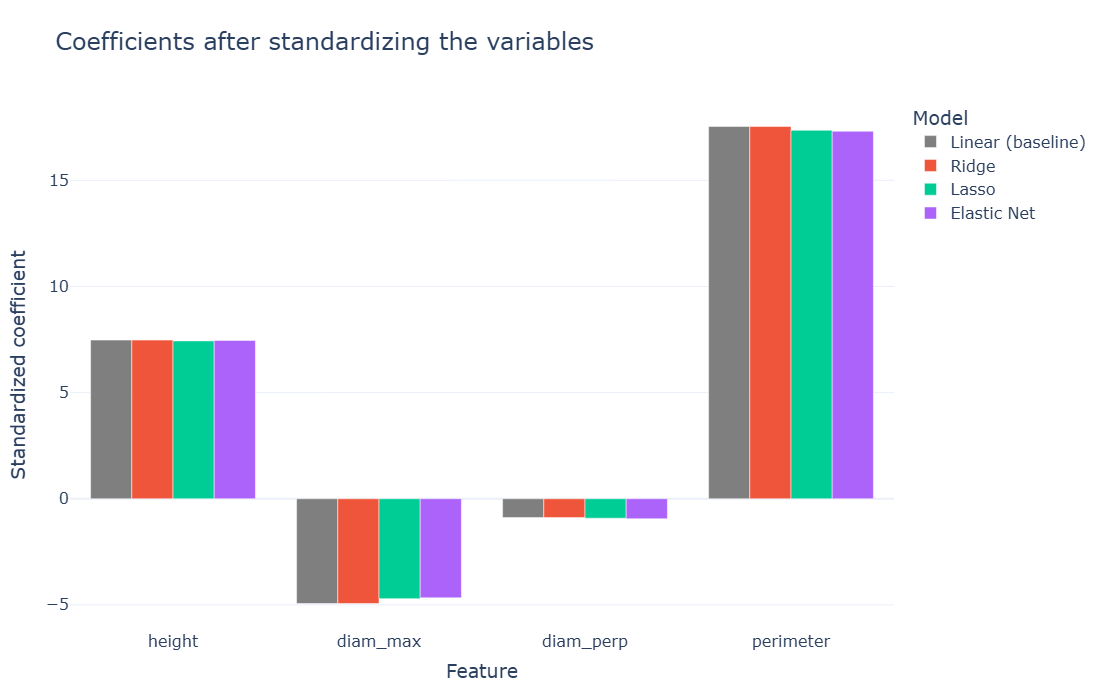

In [127]:
rows = []
for name in [BASELINE, "Ridge", "Lasso", "Elastic Net"]:
    m = models[name]
    est = m.best_estimator_ if hasattr(m, "best_estimator_") else m
    for feat, coef in zip(FEATURES, est[-1].coef_):
        rows.append({"Model": name, "Feature": feat, "Standardized coefficient": coef})

fig = px.bar(pd.DataFrame(rows), x="Feature", y="Standardized coefficient", color="Model",
             barmode="group", color_discrete_map={BASELINE: "#7F7F7F"},
             title="Coefficients after standardizing the variables")
show(fig, height=700)

## 8. Actual vs predicted (test set)

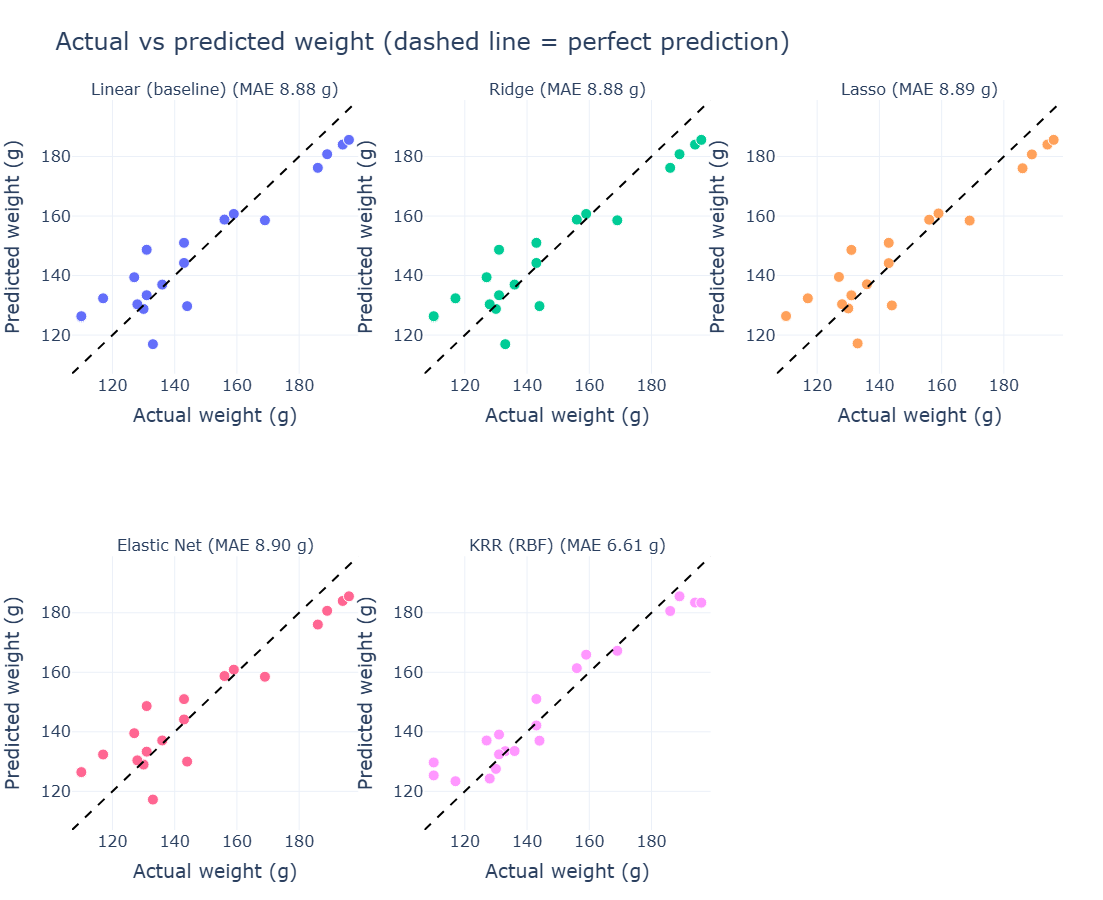

In [129]:
names = list(models)
fig = make_subplots(rows=2, cols=3, subplot_titles=[
    f"{n} (MAE {results[n]:.2f} g)" for n in names])
lims = [min(y_test.min(), min(p.min() for p in predictions.values())) - 3,
        max(y_test.max(), max(p.max() for p in predictions.values())) + 3]

for i, name in enumerate(names):
    r, c = i // 3 + 1, i % 3 + 1
    fig.add_trace(go.Scatter(x=y_test, y=predictions[name], mode="markers", name=name,
                             marker=dict(size=11, line=dict(width=1, color="white")),
                             showlegend=False), row=r, col=c)
    fig.add_trace(go.Scatter(x=lims, y=lims, mode="lines", showlegend=False,
                             line=dict(dash="dash", color="black")), row=r, col=c)
    fig.update_xaxes(title_text="Actual weight (g)", range=lims, row=r, col=c)
    fig.update_yaxes(title_text="Predicted weight (g)", range=lims, row=r, col=c)
fig.update_layout(title="Actual vs predicted weight (dashed line = perfect prediction)")
show(fig, height=900)

## 9. Live demo (10/19/2026)


New Measurements: height, diam_max, diam_perp, perimeter.
![Apple on a scale](image2.png)

In [132]:
# testing ---
## dummies to be replac---
new_apples = pd.DataFrame(
    [[8.0, 7, 6, 23.5],
     [6.5, 7.5, 7, 24.5],
     [7, 7.5, 6, 23],
     [6.5, 7.5, 6.5, 24],
    [7, 8, 7.5, 22]], columns=FEATURES)

best_name = comparison.index[0]            
print("Best model:", best_name)

demo = new_apples.copy()
demo["predicted_weight_g"] = np.round(predict_weight(best_name, new_apples), 1)
demo

Best model: KRR (RBF)


,height,diam_max,diam_perp,perimeter,predicted_weight_g
0,8.0,7.0,6.0,23.5,149.6
1,6.5,7.5,7.0,24.5,157.1
2,7.0,7.5,6.0,23.0,129.1
3,6.5,7.5,6.5,24.0,124.2
4,7.0,8.0,7.5,22.0,140.0


In [157]:
## testing
## dummies to be replac---
new_apples = pd.DataFrame(
    [[8.0, 7, 6, 23.5],
     [6.5, 7.5, 7, 24.5],
     [7, 7.5, 6, 23],
     [6.5, 7.5, 6.5, 24],
    [7, 8, 7.5, 22]], columns=FEATURES)


real_weights = [184, 193, 187, 194, 146]

best_name = comparison.index[0]            # model with the lowest test MAE
print("Best model:", best_name)

demo = new_apples.copy()
pred = predict_weight(best_name, new_apples)
demo["predicted_weight_g"] = np.round(pred, 1)

if real_weights is not None:
    demo["real_weight_g"] = real_weights
    demo["error_g"] = (demo["predicted_weight_g"] - demo["real_weight_g"]).abs().round(1)
    demo_mae = mean_absolute_error(real_weights, pred)
    print(f"Demo MAE: {demo_mae:.2f} g")
    print(f"Demo score (1 / MAE): {1 / demo_mae:.3f}")

demo

Best model: KRR (RBF)
Demo MAE: 40.80 g
Demo score (1 / MAE): 0.025


,height,diam_max,diam_perp,perimeter,predicted_weight_g,real_weight_g,error_g
0,8.0,7.0,6.0,23.5,149.6,184,34.4
1,6.5,7.5,7.0,24.5,157.1,193,35.9
2,7.0,7.5,6.0,23.0,129.1,187,57.9
3,6.5,7.5,6.5,24.0,124.2,194,69.8
4,7.0,8.0,7.5,22.0,140.0,146,6.0


In [134]:
# Same apples, every model side by side  -- to see how much they agree
## testing
side_by_side = new_apples.copy()
for name in models:
    side_by_side[name] = np.round(predict_weight(name, new_apples), 1)
side_by_side

,height,diam_max,diam_perp,perimeter,Linear (baseline),Ridge,Lasso,Elastic Net,KRR (RBF)
0,8.0,7.0,6.0,23.5,200.1,200.1,199.7,199.8,149.6
1,6.5,7.5,7.0,24.5,178.5,178.5,178.4,178.3,157.1
2,7.0,7.5,6.0,23.0,166.5,166.5,166.6,166.7,129.1
3,6.5,7.5,6.5,24.0,172.0,172.0,171.9,171.9,124.2
4,7.0,8.0,7.5,22.0,138.7,138.7,139.2,139.3,140.0
